In [18]:
import sys
sys.path.append("..")

import numpy as np
from matplotlib import pyplot as plt

from nes.models import NPolynome, Spherical
from nes.dists import DiagNormal, XDiagNormal
from nes import VizOptimizer

## Models examples


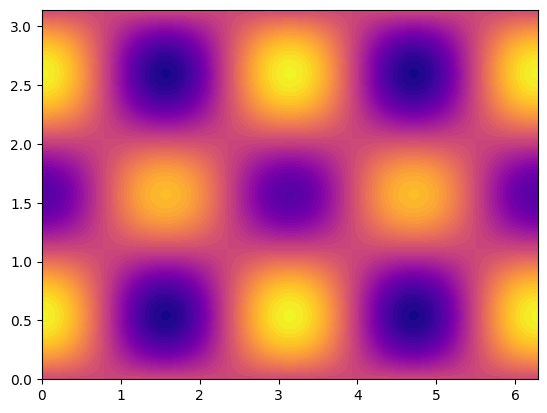

In [19]:
smodel = Spherical(3, 1)
fig, ax = plt.subplots()
smodel.plot_fitness(ax, smodel.lower, smodel.upper)
plt.show()

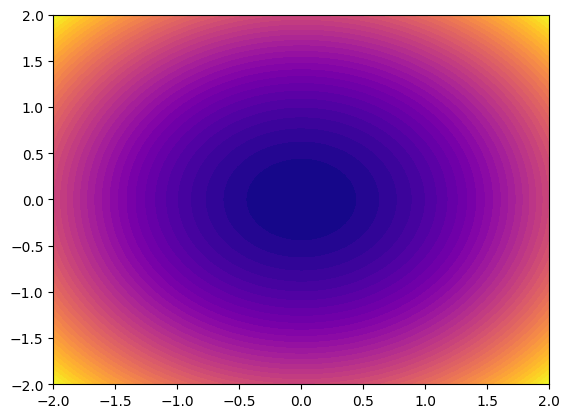

In [20]:
model = NPolynome(np.array(
    [
        [0, 0],
        [0, 0],
        [2, 2],
    ]
    ))
model.lower = np.array([-2, -2])
model.upper = np.array([2, 2])
dist = DiagNormal(2)
fig, ax = plt.subplots()
model.plot_fitness(ax, model.lower, model.upper)
plt.show()

## Optimizeing using Dist.from_model

Optimum at [ 1.73835251e-06 -5.67991024e-07]


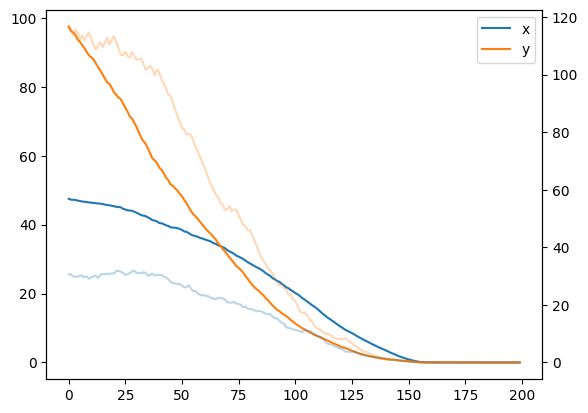

In [21]:
fig, ax = plt.subplots()
samples = 500
dim = 2
params = np.zeros((10, dim))
params[2, :] = 2
model = NPolynome(params)
model.upper = np.array([100, 200])
model.lower = np.full((dim), -5)

# using the from model factory enables far easier usage
dist = DiagNormal.from_model(model)
dist.learning_rate = 0.5
opt = VizOptimizer.using_axis(ax,model, dist, samples)
for _ in range(200):
    opt.step()
    ax.set_xbound()
opt.plot_series()
optimum = opt.dist.get_optimum()
print(f"Optimum at {optimum}")

## Flat Parts
Now a bit more complex Situation since it is very flat at the bottom.

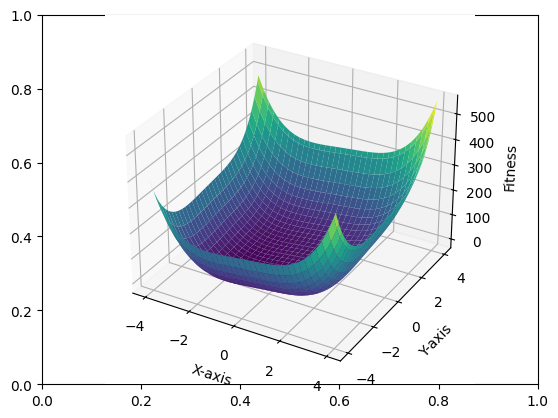

In [22]:
samples = 256
dim = 2
params = np.zeros((10, dim))
params[2, :] = -1
params[4, :] = 1
params[1, :] = 10
init_params = np.array([5, 5, 0.1, 0.1], dtype=np.float64)

fig, ax = plt.subplots()
model = NPolynome(params)
model.upper = np.full((dim), 4)
model.lower = np.full((dim), -4)
n: int = 101
phis = np.linspace(model.lower[0], model.upper[0], n)
thetas = np.linspace(model.lower[1], model.upper[1], n)
x, y = np.meshgrid(phis, thetas)
samples = np.array([x, y]).reshape(2, -1).T
fitness = model.evaluate_samples(samples).reshape(x.shape)
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x, y, fitness, cmap='viridis')
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Fitness')
plt.show()

array([-1.47970547, -1.47968627])

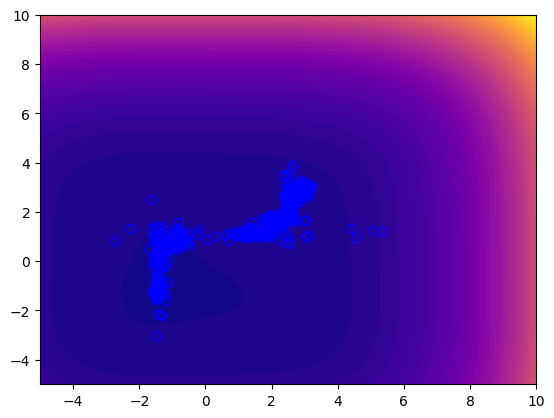

In [27]:
samples = 256
dim = 2
params = np.zeros((10, dim))
params[2, :] = -1
params[4, :] = 1
params[1, :] = 10
init_params = np.array([3, 3, 0.1, 0.1], dtype=np.float64)

fig, ax = plt.subplots()
model = NPolynome(params)
model.upper = np.full((dim), 10)
model.lower = np.full((dim), -5)
dist = XDiagNormal.from_model(model)
dist.learning_rate = 0.5
dist.set_init_params(init_params)
opt = VizOptimizer.using_axis(ax,model, dist, samples)
opt.plot_fitness()
for _ in range(1000):
    opt.step(show=True)
    ax.set_xbound()
opt.dist.get_optimum()

array([-1.4770516 , -1.47969535])

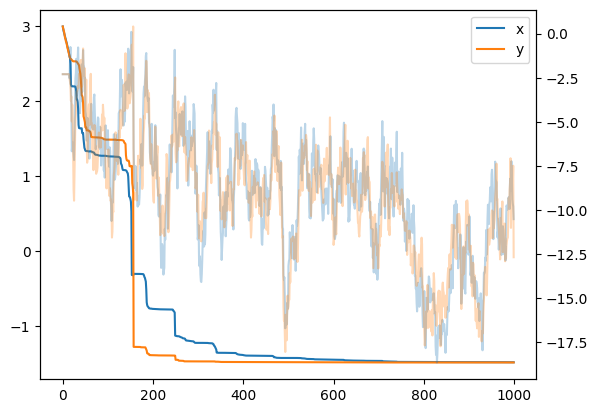

In [26]:
samples = 256
dim = 2
params = np.zeros((10, dim))
params[2, :] = -1
params[4, :] = 1
params[1, :] = 10
init_params = np.array([3, 3, 0.1, 0.1], dtype=np.float64)

fig, ax = plt.subplots()
model = NPolynome(params)
model.upper = np.full((dim), 5)
model.lower = np.full((dim), -5)
dist = XDiagNormal.from_model(model)
dist.learning_rate = 0.5
dist.set_init_params(init_params)
opt = VizOptimizer.using_axis(ax,model, dist, samples)
# opt.plot_fitness()
for _ in range(1000):
    opt.step(show=False)
    ax.set_xbound()
opt.plot_series()
opt.dist.get_optimum()